# NewsMood — 01. Exploration des données

**Objectif :** connaître nos données avant de modéliser.
- Combien d'articles, par entreprise, par source et par jour ?
- Quelle est la qualité des textes ?
- Y a-t-il des doublons cachés ?

In [1]:
# --- Imports et chargement des donnees -------------------------------
import sys
from pathlib import Path

# Le notebook est dans notebooks/ : on ajoute la racine du projet au chemin
# de Python, pour pouvoir importer nos fichiers du dossier src/.
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.database import get_connection

# On charge les deux tables de la base dans des DataFrames pandas
conn = get_connection()
articles = pd.read_sql("SELECT * FROM articles", conn)
prices = pd.read_sql("SELECT * FROM prices", conn)

print("Articles :", articles.shape)   # (nombre de lignes, nombre de colonnes)
print("Prix     :", prices.shape)

articles.head()   # affiche les 5 premieres lignes

Articles : (192, 8)
Prix     : (195, 4)


,id,ticker,source,title,text,url,published_at,collected_at
0,1,AAPL,Yahoo Finance,Apple's Market Value Grew From $350 Billion to...,Apple (AAPL +0.43%) is back in the $5 trillion...,https://www.fool.com/investing/2026/10/17/appl...,2026-10-17T20:07:00+00:00,2026-10-18T11:38:02+00:00
1,2,AAPL,Yahoo Finance,Apple bets on the same Siri AI technology with...,"Apple's latest tech move is HomeView, a smart-...",https://finance.yahoo.com/technology/ai/articl...,2026-10-17T18:30:00+00:00,2026-10-18T11:38:05+00:00
2,3,AAPL,Yahoo Finance,"$10,000 Invested in Apple Could Be Worth This ...",Apple (AAPL +0.43%) has delivered extraordinar...,https://www.fool.com/investing/2026/10/17/usd1...,2026-10-17T15:49:02+00:00,2026-10-18T11:38:07+00:00
3,4,AAPL,Yahoo Finance,"Apple, Nvidia each gave $25M to Trump's White ...",A leaked list of Trump White House ballroom do...,https://finance.yahoo.com/economy/policy/artic...,2026-10-17T15:00:00+00:00,2026-10-18T11:38:10+00:00
4,5,AAPL,Yahoo Finance,"Apple’s $1,999 Foldable iPhone Sold Out in Min...",Apple (NASDAQ:AAPL | AAPL Price Prediction) op...,https://247wallst.com/investing/2026/10/17/app...,2026-10-17T14:50:18+00:00,2026-10-18T11:38:12+00:00


## 1. Répartition des articles par entreprise et par source

In [2]:
# Tableau croise : une ligne par source, une colonne par entreprise.
# margins=True ajoute les totaux.
pd.crosstab(articles["source"], articles["ticker"], margins=True, margins_name="Total")

ticker,AAPL,NVDA,TSLA,Total
source,,,,
Nasdaq,15,15,15,45
Seeking Alpha,30,30,30,90
Yahoo Finance,19,22,16,57
Total,64,67,61,192


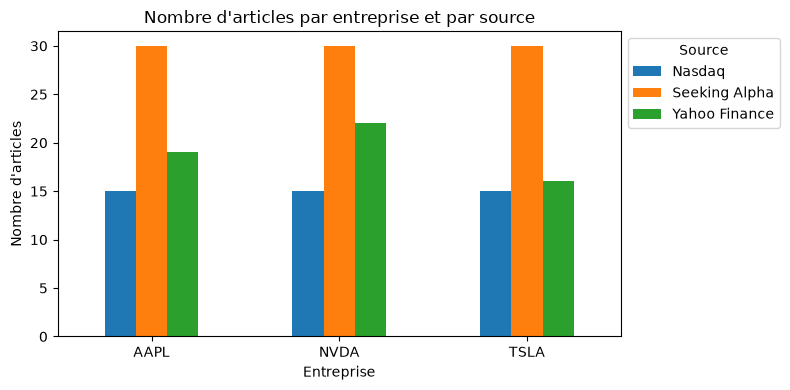

In [3]:
# Meme information, sous forme de diagramme en barres
ax = pd.crosstab(articles["ticker"], articles["source"]).plot(kind="bar", figsize=(8, 4))
ax.set_title("Nombre d'articles par entreprise et par source")
ax.set_xlabel("Entreprise")
ax.set_ylabel("Nombre d'articles")
plt.xticks(rotation=0)   # etiquettes horizontales
ax.legend(title="Source", loc="upper left", bbox_to_anchor=(1, 1))  # legende a droite, hors du graphique
plt.tight_layout()
plt.show()

In [4]:
from urllib.parse import urlparse

# On extrait le nom de domaine de l'URL : https://www.fool.com/... -> fool.com
articles["publisher"] = articles["url"].apply(lambda u: urlparse(u).netloc.replace("www.", ""))

# Les editeurs des articles du flux Yahoo Finance
articles[articles["source"] == "Yahoo Finance"]["publisher"].value_counts()

publisher
fool.com             32
finance.yahoo.com    12
stocktwits.com        4
247wallst.com         3
tikr.com              2
investopedia.com      2
thestreet.com         1
marketbeat.com        1
Name: count, dtype: int64

**Constats :**
- **Entreprises équilibrées :** 64 articles pour AAPL, 67 pour NVDA, 61 pour TSLA. Les comparaisons entre entreprises seront donc justes.
- **Sources déséquilibrées :** Seeking Alpha fournit 47 % des articles (90 / 192), mais seulement des titres. Les textes complets viennent tous de Yahoo Finance.
- **Biais d'éditeur :** Yahoo Finance reprend surtout des articles de The Motley Fool (32 / 57, soit 56 %), un éditeur de conseils d'investissement souvent optimistes. Le sentiment des textes complets reflétera donc surtout son ton : à vérifier en Phase 4 avec la colonne `publisher`.

## 2. Qualité des textes

In [5]:
# Pour chaque source : nombre d'articles, et combien ont un texte complet
couverture = articles.groupby("source").agg(
    articles=("id", "count"),
    avec_texte=("text", lambda s: s.notna().sum()),   # notna() = "n'est pas vide"
)
couverture["pourcentage"] = (couverture["avec_texte"] / couverture["articles"] * 100).round(1)
couverture

,articles,avec_texte,pourcentage
source,,,
Nasdaq,45,0,0.0
Seeking Alpha,90,0,0.0
Yahoo Finance,57,52,91.2


--- Longueur des textes complets ---
count      52.0
mean     4387.0
std      1716.0
min      1439.0
25%      3400.0
50%      4476.0
75%      5141.0
max      9826.0
Name: text_len, dtype: float64

--- Longueur des titres, par source ---
               count  mean   std   min   25%   50%    75%    max
source                                                          
Nasdaq          45.0  81.0  32.0  38.0  58.0  75.0   90.0  173.0
Seeking Alpha   90.0  65.0  14.0  22.0  57.0  66.0   75.0  104.0
Yahoo Finance   57.0  82.0  36.0  30.0  56.0  79.0  103.0  214.0


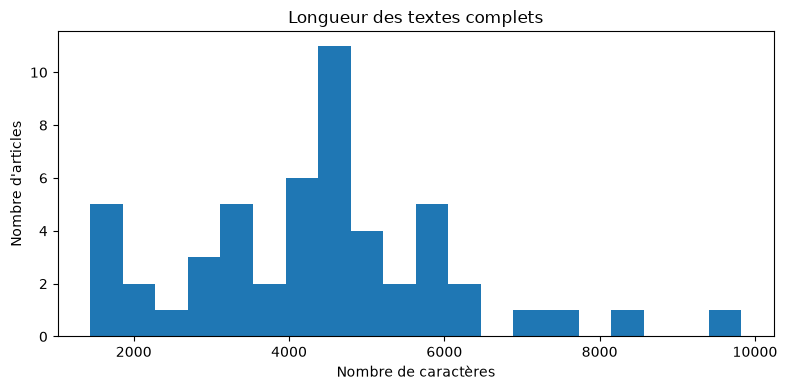

In [6]:
# Longueur en nombre de caracteres
articles["text_len"] = articles["text"].str.len()
articles["title_len"] = articles["title"].str.len()

print("--- Longueur des textes complets ---")
print(articles["text_len"].describe().round(0))

print("\n--- Longueur des titres, par source ---")
print(articles.groupby("source")["title_len"].describe().round(0))

# Histogramme : comment se repartissent les longueurs des textes ?
fig, ax = plt.subplots(figsize=(8, 4))
articles["text_len"].dropna().plot(kind="hist", bins=20, ax=ax)
ax.set_title("Longueur des textes complets")
ax.set_xlabel("Nombre de caractères")
ax.set_ylabel("Nombre d'articles")
plt.tight_layout()
plt.show()

In [7]:
# Meme entreprise + meme titre, mais URL differentes = probablement le meme article
doublons = articles[articles.duplicated(subset=["ticker", "title"], keep=False)]
print("Nombre de lignes concernees :", len(doublons))
doublons.sort_values("title")[["ticker", "source", "publisher", "title"]]

Nombre de lignes concernees : 20


,ticker,source,publisher,title
2,AAPL,Yahoo Finance,fool.com,"$10,000 Invested in Apple Could Be Worth This ..."
23,AAPL,Nasdaq,nasdaq.com,"$10,000 Invested in Apple Could Be Worth This ..."
0,AAPL,Yahoo Finance,fool.com,Apple's Market Value Grew From $350 Billion to...
21,AAPL,Nasdaq,nasdaq.com,Apple's Market Value Grew From $350 Billion to...
6,AAPL,Yahoo Finance,fool.com,Apple's New Home Collection Gives Investors An...
24,AAPL,Nasdaq,nasdaq.com,Apple's New Home Collection Gives Investors An...
61,TSLA,Nasdaq,nasdaq.com,BYD or Tesla: Which Is a Better Stock?
56,TSLA,Yahoo Finance,fool.com,BYD or Tesla: Which Is a Better Stock?
43,TSLA,Yahoo Finance,fool.com,Elon Musk Says Optimus Is Tesla's Most Importa...
57,TSLA,Nasdaq,nasdaq.com,Elon Musk Says Optimus Is Tesla's Most Importa...


In [8]:
# On normalise le titre : sans espaces au debut ou a la fin, en minuscules.
# Comme ca, "Apple Rises" et "apple rises " sont reconnus comme identiques.
articles["title_norm"] = articles["title"].str.strip().str.lower()

# 1. On trie pour mettre en premier les articles qui ont le texte le plus long
#    (na_position="last" : les articles sans texte passent a la fin).
# 2. Pour chaque (entreprise, titre), on garde seulement la premiere ligne.
# 3. On remet l'ordre d'origine.
articles_clean = (
    articles.sort_values("text_len", ascending=False, na_position="last", kind="stable")
            .drop_duplicates(subset=["ticker", "title_norm"], keep="first")
            .sort_values("id")
)

print("Avant :", len(articles), "| Apres :", len(articles_clean),
      "| Retires :", len(articles) - len(articles_clean))
articles_clean["source"].value_counts()

Avant : 192 | Apres : 182 | Retires : 10


source
Seeking Alpha    90
Yahoo Finance    57
Nasdaq           35
Name: count, dtype: int64

**Constat — doublons entre sources :**
- 10 articles du flux Nasdaq (22 % de cette source) sont des copies d'articles déjà présents dans le flux Yahoo Finance (9 du Motley Fool, 1 de MarketBeat), publiés sous une autre URL.
- Sans correction, ces articles compteraient deux fois dans le sentiment moyen. Pour l'analyse, on garde un seul exemplaire par (entreprise, titre), en privilégiant la version avec texte complet : 192 → 182 articles. La base brute n'est pas modifiée.

## 3. Dimension temporelle

Article le plus ancien : 2026-10-08 18:36:49+00:00
Article le plus récent : 2026-10-18 11:50:00+00:00
Articles sans date     : 0


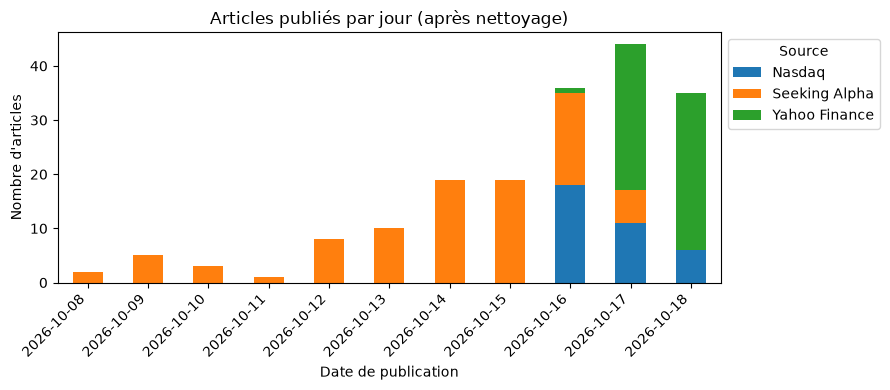

source,Nasdaq,Seeking Alpha,Yahoo Finance
date,,,
2026-10-08,0,2,0
2026-10-09,0,5,0
2026-10-10,0,3,0
2026-10-11,0,1,0
2026-10-12,0,8,0
2026-10-13,0,10,0
2026-10-14,0,19,0
2026-10-15,0,19,0
2026-10-16,18,17,1


In [9]:
# On convertit le texte des dates en vraies dates (fuseau UTC)
articles["published_at"] = pd.to_datetime(articles["published_at"], utc=True)
articles_clean["published_at"] = pd.to_datetime(articles_clean["published_at"], utc=True)
articles_clean["date"] = articles_clean["published_at"].dt.date

print("Article le plus ancien :", articles_clean["published_at"].min())
print("Article le plus récent :", articles_clean["published_at"].max())
print("Articles sans date     :", articles_clean["published_at"].isna().sum())

# Nombre d'articles par jour et par source
par_jour = pd.crosstab(articles_clean["date"], articles_clean["source"])
ax = par_jour.plot(kind="bar", stacked=True, figsize=(9, 4))
ax.set_title("Articles publiés par jour (après nettoyage)")
ax.set_xlabel("Date de publication")
ax.set_ylabel("Nombre d'articles")
ax.legend(title="Source", loc="upper left", bbox_to_anchor=(1, 1))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

par_jour

In [10]:
# Sur les donnees brutes (= ce que contiennent vraiment les flux) :
# pour chaque entreprise et source, combien d'heures entre le plus ancien et le plus recent ?
fenetre = articles.groupby(["ticker", "source"])["published_at"].agg(["count", "min", "max"])
fenetre["fenetre_heures"] = ((fenetre["max"] - fenetre["min"]).dt.total_seconds() / 3600).round(1)
fenetre[["count", "fenetre_heures"]]

count  fenetre_heures
ticker source                              
AAPL   Nasdaq            15            36.0
       Seeking Alpha     30           211.6
       Yahoo Finance     19            33.5
NVDA   Nasdaq            15            36.1
       Seeking Alpha     30           188.5
       Yahoo Finance     22             2.8
TSLA   Nasdaq            15            41.7
       Seeking Alpha     30           128.8
       Yahoo Finance     16            29.3

In [11]:
# Les articles Yahoo de Nvidia, du plus ancien au plus recent
nvda_yahoo = articles[(articles["ticker"] == "NVDA") & (articles["source"] == "Yahoo Finance")]
nvda_yahoo.sort_values("published_at")[["published_at", "publisher", "title"]]

,published_at,publisher,title
98,2026-10-18 09:03:00+00:00,fool.com,1 Reason TSMC Stock Could Rally After Its Reco...
104,2026-10-18 09:04:00+00:00,fool.com,3 High-Yield Energy Stocks to Load Up on This ...
103,2026-10-18 09:08:01+00:00,fool.com,President Trump Sells Micron Stock and Buys An...
97,2026-10-18 09:10:00+00:00,fool.com,Could Investing $200 Per Month in VOO Make You...
96,2026-10-18 09:20:02+00:00,fool.com,I Just Bought More Realty Income (O) Stock. He...
102,2026-10-18 09:25:00+00:00,fool.com,Look Who's Using D2C Satellite Phones Now!
86,2026-10-18 09:30:00+00:00,fool.com,"Prediction: $1,000 Invested in Taiwan Semicond..."
95,2026-10-18 09:37:02+00:00,fool.com,A Record Number of S&P 500 Companies Issued Up...
94,2026-10-18 09:40:00+00:00,fool.com,Is Centrus Energy Stock a Millionaire Maker?
93,2026-10-18 09:50:00+00:00,fool.com,Can Alphabet Stock Double By 2030?


## 4. Pertinence des articles

In [12]:
from src.config import TICKERS

def mentionne_entreprise(row):
    """True si le titre ou le texte cite le nom de l'entreprise ou son symbole."""
    nom = TICKERS[row["ticker"]].lower()            # ex : "nvidia"
    symbole = row["ticker"].lower()                 # ex : "nvda"
    texte = row["text"] if isinstance(row["text"], str) else ""   # texte vide si absent
    contenu = (row["title"] + " " + texte).lower()
    return nom in contenu or symbole in contenu

# axis=1 : la fonction est appliquee a chaque ligne
articles_clean["pertinent"] = articles_clean.apply(mentionne_entreprise, axis=1)

# Pour chaque entreprise et source : nombre d'articles, nombre de pertinents, pourcentage
pertinence = articles_clean.groupby(["ticker", "source"])["pertinent"].agg(["count", "sum", "mean"])
pertinence.columns = ["articles", "pertinents", "pourcentage"]
pertinence["pourcentage"] = (pertinence["pourcentage"] * 100).round(1)
pertinence

articles  pertinents  pourcentage
ticker source                                          
AAPL   Nasdaq               11           3         27.3
       Seeking Alpha        30          25         83.3
       Yahoo Finance        19          18         94.7
NVDA   Nasdaq               14           4         28.6
       Seeking Alpha        30          26         86.7
       Yahoo Finance        22           3         13.6
TSLA   Nasdaq               10           6         60.0
       Seeking Alpha        30          23         76.7
       Yahoo Finance        16          14         87.5

In [13]:
# Jeu de donnees final pour l'analyse : dedoublonne ET pertinent
articles_final = articles_clean[articles_clean["pertinent"]].copy()

print("Après dédoublonnage :", len(articles_clean),
      "| Après filtre de pertinence :", len(articles_final))

pd.crosstab(articles_final["source"], articles_final["ticker"], margins=True, margins_name="Total")

Après dédoublonnage : 182 | Après filtre de pertinence : 122


ticker,AAPL,NVDA,TSLA,Total
source,,,,
Nasdaq,3,4,6,13
Seeking Alpha,25,26,23,74
Yahoo Finance,18,3,14,35
Total,46,33,43,122


In [14]:
# Verification : le module src/cleaning.py donne-t-il exactement le meme resultat ?
from src.cleaning import load_clean_articles

verif = load_clean_articles()
print("Notebook :", len(articles_final), "articles | Module :", len(verif), "articles")

# assert arrete tout avec une erreur si la condition est fausse
assert sorted(verif["id"]) == sorted(articles_final["id"]), "Les deux méthodes donnent des résultats différents !"
print("Le module donne exactement les mêmes articles que le notebook")

Notebook : 122 articles | Module : 122 articles
Le module donne exactement les mêmes articles que le notebook


## 5. Conclusions de l'exploration

| Étape | Articles | Retirés |
| --- | --- | --- |
| Données brutes | 192 | — |
| Après dédoublonnage | 182 | 10 |
| Après filtre de pertinence | **122** | 60 |

1. **Qualité des textes :** 52 textes complets, tous issus du flux Yahoo Finance, de 1 439 à 9 826 caractères. L'histogramme ne montre aucune page anti-robot résiduelle.
2. **Doublons entre sources :** Nasdaq republie des articles du Motley Fool déjà présents dans Yahoo (10 cas). On garde un seul exemplaire, de préférence avec texte.
3. **Pertinence :** le flux Yahoo « NVDA » ne contient que 14 % d'articles sur Nvidia (le reste : articles généraux du Motley Fool), et les flux Nasdaq 27 à 60 %. On ne garde que les articles qui citent l'entreprise.
4. **Biais à surveiller :** le Motley Fool fournit la majorité des textes complets, et le mélange des sources varie selon les jours (Seeking Alpha seul avant le 16/10). Les comparaisons se feront aussi source par source.
5. **Fréquence de collecte :** les flux pertinents couvrent au moins 29 heures. Deux collectes par jour suffisent.

**Pour la suite :** toutes les analyses utilisent `load_clean_articles()` (module `src/cleaning.py`), qui applique ces règles de façon reproductible.